# 0.4 — Auditoria independente de duplicatas do dataset

**Projeto:** Sistema de Detecção de Rostos Sintéticos Gerados por Inteligência Artificial  
**Referência:** `training/notebooks/0.1_resnet34_224.ipynb` · cenário `source_holdout` · semente 42  
**Objetivo:** auditar **os dados e as partições originais** utilizados nas seis configurações (ResNet18/34/50 com e sem FFT)

### Por que existem duas pastas?

| Diretório | Papel no experimento |
|---|---|
| `training/dataset/` | Imagens **originais** (`fake/`, `real/`), antes do detector; 16.000 registros no experimento. |
| `training/dataset_faces_224_m15_yunet_v1/` | **Crops válidos** produzidos pelo YuNet (um rosto, margem 15%, 224×224); 15.960 imagens após 40 rejeições. |

Essas duas pastas estão no `.gitignore` de `training/`. **Precisam existir no computador que executará este notebook**; baixar só o código do GitHub não fornece as imagens. Os caminhos absolutos antigos encontrados nos CSVs são adaptados automaticamente para o diretório local.

### O que esta auditoria produz

1. Contagens e validação de **integridade dos crops em relação ao manifesto do treinamento** (SHA-256).
2. Busca de **arquivos binariamente idênticos** nos originais e nos crops (SHA-256).
3. Reprodução da triagem perceptual **dHash de 64 bits** e distância de Hamming **≤ 5**, como no notebook oficial, com ordenação complementar por pHash para auxiliar a inspeção.
4. **Planilha de revisão humana** dos pares em partições diferentes e **pranchas de imagens** lado a lado.
5. Relatório com **o que foi comprovado**, o que foi apenas apontado como candidato e o que **permanece pendente ou inconclusivo**.

> **Importante:** dHash/pHash não provam duplicação nem a mesma identidade. Pares entre conjuntos exigem verificação visual e, quando necessário, metadados de origem. O relatório nunca converte candidatos em “vazamentos confirmados” automaticamente.

**Bibliotecas:** `pandas`, `numpy`, `opencv-python` (`cv2`), `Pillow`, `IPython`. Todas fazem parte ou são compatíveis com o ambiente de treinamento. O notebook só escreve relatórios em `training/analysis/auditoria_duplicatas/`, que já está coberto pelo `.gitignore` de `training/`.

## 1. Configuração e localização dos diretórios

In [1]:
from __future__ import annotations

import hashlib
import json
from collections import defaultdict
from datetime import datetime, timezone
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageOps
from IPython.display import display

# Configure apenas se abrir o notebook fora da estrutura usual do projeto.
PROJETO_DIR_MANUAL = None  # Ex.: Path('/home/usuario/Documents/synthetic-face-detection')

# Valores efetivamente usados na ResNet34 de referência.
TAMANHO_ESPERADO_RAW = 16_000
TAMANHO_ESPERADO_CROPS = 15_960
PARTICOES_ESPERADAS = {'train': 9_576, 'validation': 2_394, 'test': 3_990}
LIMIAR_DHASH = 5

# Exibir imagens em pranchas sem gravá-las no repositório.
GERAR_PRANCHAS_PRIORITARIAS = True
LIMIAR_PRIORIDADE = 2  # Pares com dHash <= 2 são revisados primeiro.
GERAR_PRANCHAS_TODOS_CROSS_SPLIT = False  # Pode gerar muitos arquivos; use apenas se necessário.
PARES_POR_PRANCHA = 8


def localizar_projeto() -> Path:
    if PROJETO_DIR_MANUAL is not None:
        candidato = Path(PROJETO_DIR_MANUAL).expanduser().resolve()
        if not (candidato / 'training' / 'notebooks').is_dir():
            raise FileNotFoundError(f'PROJETO_DIR_MANUAL inválido: {candidato}')
        return candidato
    atual = Path.cwd().resolve()
    for candidato in (atual, *atual.parents):
        if (candidato / 'training' / 'notebooks').is_dir() and (candidato / 'models' / 'audit' / 'resnet34').is_dir():
            return candidato
    raise FileNotFoundError(
        'Não encontrei a raiz do projeto. Execute de training/notebooks, '
        'training ou da raiz, ou defina PROJETO_DIR_MANUAL.'
    )


PROJETO_DIR = localizar_projeto()
TREINO_DIR = PROJETO_DIR / 'training'
RAW_DIR = TREINO_DIR / 'dataset'
CROPS_DIR = TREINO_DIR / 'dataset_faces_224_m15_yunet_v1'
AUDITORIA_REFERENCIA_DIR = PROJETO_DIR / 'models' / 'audit' / 'resnet34'
SAIDA_DIR = TREINO_DIR / 'analysis' / 'auditoria_duplicatas'
PRANCHAS_DIR = SAIDA_DIR / 'pranchas'

ARQUIVO_SPLITS = AUDITORIA_REFERENCIA_DIR / 'resnet34_224_source_holdout_seed42_splits.csv'
ARQUIVO_MANIFESTO = AUDITORIA_REFERENCIA_DIR / 'resnet34_224_dataset_manifest.csv'
ARQUIVO_CANDIDATOS_EXISTENTE = AUDITORIA_REFERENCIA_DIR / 'resnet34_224_near_duplicate_candidates.csv'
ARQUIVO_IDENTIDADES = AUDITORIA_REFERENCIA_DIR / 'resnet34_224_identity_origin_review.csv'

for pasta, nome in [(RAW_DIR, 'dataset original'), (CROPS_DIR, 'crops YuNet')]:
    if not pasta.is_dir():
        raise FileNotFoundError(f'Pasta de {nome} não encontrada: {pasta}\nAs imagens estão no .gitignore e não são baixadas com git clone.')
for arquivo in [ARQUIVO_SPLITS, ARQUIVO_MANIFESTO]:
    if not arquivo.is_file():
        raise FileNotFoundError(f'Manifesto oficial necessário não encontrado: {arquivo}')

SAIDA_DIR.mkdir(parents=True, exist_ok=True)
PRANCHAS_DIR.mkdir(parents=True, exist_ok=True)

print('Projeto:              ', PROJETO_DIR)
print('Originais:            ', RAW_DIR)
print('Crops 224×224:       ', CROPS_DIR)
print('Manifestos oficiais: ', AUDITORIA_REFERENCIA_DIR)
print('Relatórios da revisão:', SAIDA_DIR)
print('OpenCV:', cv2.__version__, '| pandas:', pd.__version__)

Projeto:               /home/guilhermemathiasreis/Documents/synthetic-face-detection
Originais:             /home/guilhermemathiasreis/Documents/synthetic-face-detection/training/dataset
Crops 224×224:        /home/guilhermemathiasreis/Documents/synthetic-face-detection/training/dataset_faces_224_m15_yunet_v1
Manifestos oficiais:  /home/guilhermemathiasreis/Documents/synthetic-face-detection/models/audit/resnet34
Relatórios da revisão: /home/guilhermemathiasreis/Documents/synthetic-face-detection/training/analysis/auditoria_duplicatas
OpenCV: 5.0.0 | pandas: 3.0.2


## 2. Ler os manifestos **sem refazer a divisão**

O treinamento grava em CSV tanto a lista das imagens válidas quanto a associação exata a `train`, `validation` e `test`. Este notebook **não executa `train_test_split`**: reutiliza os registros originais.

O `path` nos arquivos pode conter o diretório absoluto da máquina em que se treinou; aqui o trecho a partir de `/training/` é reapontado para a máquina atual. Também será conferida a existência de cada imagem e sua correspondência a uma única partição.

In [2]:
EXTENSOES_IMAGENS = {'.jpg', '.jpeg', '.png', '.bmp', '.ppm', '.pgm', '.tif', '.tiff', '.webp'}


def caminho_local(caminho: str, pasta_esperada: Path, classe: str) -> Path:
    """Normaliza caminhos antigos (absolutos) sem mudar os CSVs oficiais."""
    texto = str(caminho).strip().replace('\\', '/')
    if not texto or texto.lower() in {'nan', 'none'}:
        return pasta_esperada / classe / '__CAMINHO_INDEFINIDO__'
    p = Path(texto)
    if texto.startswith('training/'):
        candidato = PROJETO_DIR / texto
        if candidato.is_file():
            return candidato.resolve()
    marcador = '/training/'
    if marcador in texto:
        candidato = TREINO_DIR / texto.split(marcador, 1)[1]
        if candidato.is_file():
            return candidato.resolve()
    if p.is_file():
        return p.resolve()
    # Saída oficial: training/<pasta>/fake/<nome> ou .../real/<nome>
    return (pasta_esperada / classe / p.name).resolve()


def caminho_portatil(caminho: Path) -> str:
    try:
        return caminho.resolve().relative_to(PROJETO_DIR).as_posix()
    except ValueError:
        return str(caminho.resolve())


splits = pd.read_csv(ARQUIVO_SPLITS, dtype={'path': str, 'source_path': str, 'class_name': str,
                                         'source': str, 'split': str}).fillna('')
manifesto_oficial = pd.read_csv(ARQUIVO_MANIFESTO, dtype={'path': str, 'sha256': str}).fillna('')

obrigatorias = {'path', 'source_path', 'class_name', 'source', 'split'}
if not obrigatorias.issubset(splits.columns):
    raise ValueError(f'Faltam colunas no CSV de partições: {sorted(obrigatorias - set(splits.columns))}')
if not {'path', 'sha256'}.issubset(manifesto_oficial.columns):
    raise ValueError('O manifesto de hashes deve conter path e sha256.')

splits['path_local'] = [caminho_local(p, CROPS_DIR, c) for p, c in zip(splits.path, splits.class_name)]
splits['source_path_local'] = [caminho_local(p, RAW_DIR, c) for p, c in zip(splits.source_path, splits.class_name)]
splits['path_portatil'] = splits.path_local.map(caminho_portatil)
splits['source_path_portatil'] = splits.source_path_local.map(caminho_portatil)

manifesto_oficial['path_portatil'] = [caminho_portatil(caminho_local(p, CROPS_DIR, c))
                                      for p, c in zip(manifesto_oficial.path,
                                                      manifesto_oficial.class_name if 'class_name' in manifesto_oficial.columns
                                                      else [Path(str(p)).parent.name for p in manifesto_oficial.path])]
if splits.path_portatil.duplicated().any():
    raise ValueError('O manifesto de partições possui caminhos de crops repetidos.')
if manifesto_oficial.path_portatil.duplicated().any():
    raise ValueError('O manifesto oficial de hashes possui caminhos repetidos.')
if len(splits) != TAMANHO_ESPERADO_CROPS or len(manifesto_oficial) != TAMANHO_ESPERADO_CROPS:
    raise ValueError(f'Total divergente dos {TAMANHO_ESPERADO_CROPS:,} crops esperados: '
                     f'partições={len(splits)}, hashes={len(manifesto_oficial)}.')

contagens = splits.groupby('split').size().to_dict()
if contagens != PARTICOES_ESPERADAS:
    raise ValueError(f'Partições diferentes do experimento oficial: {contagens} != {PARTICOES_ESPERADAS}')
if not set(splits.class_name).issubset({'fake', 'real'}):
    raise ValueError(f'Classes inesperadas: {set(splits.class_name)}')
if set(splits.path_portatil) != set(manifesto_oficial.path_portatil):
    raise ValueError('Os manifestos não se referem ao mesmo conjunto de crops.')

faltantes_crops = splits.loc[~splits.path_local.map(Path.is_file), 'path_portatil'].tolist()
faltantes_originais = splits.loc[~splits.source_path_local.map(Path.is_file), 'source_path_portatil'].tolist()
if faltantes_crops or faltantes_originais:
    print('Exemplos de crops ausentes:', faltantes_crops[:5])
    print('Exemplos de originais ausentes:', faltantes_originais[:5])
    raise FileNotFoundError(f'Não foi possível localizar {len(faltantes_crops)} crops '
                            f'e {len(faltantes_originais)} imagens originais. '
                            'Confirme os nomes e os diretórios locais antes de prosseguir.')

# Uma mesma imagem nunca pode pertencer simultaneamente a duas partições.
assert splits.groupby('path_portatil')['split'].nunique().max() == 1
print('✅ Foram localizados os', len(splits), 'crops e suas imagens originais.')
print('Partições:', contagens)
display(splits.groupby(['class_name', 'source', 'split']).size().rename('quantidade').to_frame())

✅ Foram localizados os 15960 crops e suas imagens originais.
Partições: {'test': 3990, 'train': 9576, 'validation': 2394}


quantidade
class_name source    split                 
fake       sd_14     train             1612
                     validation         388
           sd_21     test              2000
           stylegan2 train             1581
                     validation         418
           stylegan3 train             1605
                     validation         394
real       celebhq   test              1990
           ffhq      train             4778
                     validation        1194

## 3. Auditoria binária SHA-256 — originais e crops

O notebook principal já verificou **0 duplicatas binárias entre os crops**. Esta etapa **repete o cálculo localmente**, confirma que os bytes dos recortes ainda coincidem com o manifesto oficial e também examina os arquivos brutos da pasta `dataset`.

Se os hashes dos crops divergirem daqueles do treinamento, a execução **para**: não seria correto atribuir à ResNet34 resultados de uma cópia diferente do dataset. Nenhum arquivo de imagem é alterado.

In [3]:
def calcular_sha256(arquivo: Path) -> str:
    digest = hashlib.sha256()
    with arquivo.open('rb') as fh:
        for bloco in iter(lambda: fh.read(1024 * 1024), b''):
            digest.update(bloco)
    return digest.hexdigest()


def grupos_duplicados(tabela: pd.DataFrame, nome_origem: str) -> pd.DataFrame:
    duplicados = tabela.loc[tabela.sha256.duplicated(keep=False)].copy()
    duplicados['tipo_base'] = nome_origem
    if not duplicados.empty:
        duplicados = duplicados.sort_values(['sha256', 'path_portatil'])
    return duplicados


print('Calculando SHA-256 dos crops e conferindo os arquivos oficiais...')
splits['sha256_atual'] = [calcular_sha256(p) for p in splits.path_local]
splits = splits.merge(manifesto_oficial[['path_portatil', 'sha256']].rename(columns={'sha256': 'sha256_oficial'}),
                      on='path_portatil', how='left', validate='one_to_one')
diferencas_hash = splits.loc[splits.sha256_atual.str.lower() != splits.sha256_oficial.str.lower(),
                            ['path_portatil', 'sha256_atual', 'sha256_oficial']]
if not diferencas_hash.empty:
    arquivo_diferencas = SAIDA_DIR / 'integridade_crops_divergente.csv'
    diferencas_hash.to_csv(arquivo_diferencas, index=False)
    raise RuntimeError(f'{len(diferencas_hash)} crops não coincidem com os hashes do treinamento. '
                       f'Veja {arquivo_diferencas}. Não continue até identificar a causa.')

duplicados_crops = grupos_duplicados(
    splits.rename(columns={'sha256_atual': 'sha256'})[['path_portatil', 'class_name', 'source', 'split', 'sha256']],
    'crops_yunet',
)
duplicados_crops.to_csv(SAIDA_DIR / 'duplicatas_exatas_crops.csv', index=False)
print(f'Crops com hash binário repetido: {len(duplicados_crops)}')

print('Calculando SHA-256 dos arquivos originais...')
originais = pd.DataFrame([
    {'path_local': arq.resolve(), 'path_portatil': caminho_portatil(arq), 'class_name': classe}
    for classe in ('fake', 'real')
    for arq in sorted((RAW_DIR / classe).rglob('*'))
    if arq.is_file() and arq.suffix.lower() in EXTENSOES_IMAGENS
])
if originais.empty:
    raise FileNotFoundError('Nenhuma imagem original encontrada em dataset/fake ou dataset/real.')
if len(originais) != TAMANHO_ESPERADO_RAW:
    raise ValueError(f'Foram encontradas {len(originais)} imagens originais; esperadas {TAMANHO_ESPERADO_RAW}. '
                     'Verifique se a pasta corresponde exatamente ao dataset da execução.')

originais['sha256'] = [calcular_sha256(p) for p in originais.path_local]
particoes_por_original = splits.groupby('source_path_portatil')['split'].agg(
    lambda x: '|'.join(sorted(set(x)))
).to_dict()
originais['split'] = originais.path_portatil.map(particoes_por_original).fillna('rejeitada_no_preprocessamento')
duplicados_originais = grupos_duplicados(originais, 'dataset_original')
duplicados_originais[['path_portatil', 'class_name', 'split', 'sha256', 'tipo_base']].to_csv(
    SAIDA_DIR / 'duplicatas_exatas_originais.csv', index=False,
)
print(f'Imagens originais com hash binário repetido: {len(duplicados_originais)}')
print(f'✅ Integridade confirmada: os {len(splits):,} crops correspondem ao manifesto SHA-256 do experimento.')

Calculando SHA-256 dos crops e conferindo os arquivos oficiais...
Crops com hash binário repetido: 0
Calculando SHA-256 dos arquivos originais...
Imagens originais com hash binário repetido: 0
✅ Integridade confirmada: os 15,960 crops correspondem ao manifesto SHA-256 do experimento.


## 4. Reproduzir a busca perceptual dHash do treinamento

A função dHash abaixo usa exatamente o método registrado no notebook oficial da ResNet34: conversão para tons de cinza, `resize` 9×8, comparação entre pixels adjacentes e distância de Hamming ≤ 5. A busca por seis faixas reduz a comparação entre todos os pares possíveis.

O **pHash** é calculado como um **critério auxiliar de ordenação**, não como uma prova adicional de identidade e não substitui a lista de candidatos do dHash. Assim, continuamos compatíveis com a auditoria já executada, mas facilitamos a inspeção humana.

In [4]:
def dhash_file(arquivo: Path) -> int:
    img = cv2.imread(str(arquivo), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(f'Falha ao abrir crop: {arquivo}')
    pequena = cv2.resize(img, (9, 8), interpolation=cv2.INTER_AREA)
    return int.from_bytes(np.packbits(pequena[:, 1:] > pequena[:, :-1]).tobytes(), 'big')


def phash_file(arquivo: Path) -> int:
    img = cv2.imread(str(arquivo), cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(f'Falha ao abrir crop: {arquivo}')
    pequena = cv2.resize(img, (32, 32), interpolation=cv2.INTER_AREA).astype(np.float32)
    dct = cv2.dct(pequena)
    frequencias = dct[:8, :8]
    base = frequencias.copy().ravel()
    limiar = np.median(base[1:])  # não usa o componente DC ao definir o limiar
    return int.from_bytes(np.packbits(frequencias.ravel() > limiar).tobytes(), 'big')


def id_par(a: str, b: str) -> str:
    esquerda, direita = sorted([a, b])
    return hashlib.sha256(f'{esquerda}\n{direita}'.encode('utf-8')).hexdigest()[:20]


# Mantém a ordem do CSV oficial e a mesma regra de busca.
tabela = splits.reset_index(drop=True).copy()
print('Calculando hashes perceptuais (dHash/pHash)...')
tabela['dhash'] = [dhash_file(arq) for arq in tabela.path_local]
tabela['phash'] = [phash_file(arq) for arq in tabela.path_local]

faixas = [(0, 11), (11, 11), (22, 11), (33, 11), (44, 10), (54, 10)]
baldes = defaultdict(list)
todos_dhash = tabela.dhash.tolist()
pares_candidatos = {}
for indice, hash_atual in enumerate(todos_dhash):
    for faixa_id, (deslocamento, largura) in enumerate(faixas):
        valor_faixa = (hash_atual >> (64 - deslocamento - largura)) & ((1 << largura) - 1)
        chave = (faixa_id, valor_faixa)
        for outro_indice in baldes[chave]:
            distancia = (hash_atual ^ todos_dhash[outro_indice]).bit_count()
            if distancia <= LIMIAR_DHASH:
                pares_candidatos[(outro_indice, indice)] = distancia
        baldes[chave].append(indice)

linhas = []
for (ia, ib), distancia in pares_candidatos.items():
    a, b = tabela.iloc[ia], tabela.iloc[ib]
    linhas.append({
        'pair_id': id_par(a.path_portatil, b.path_portatil),
        'path_a': a.path_portatil, 'path_b': b.path_portatil,
        'source_path_a': a.source_path_portatil, 'source_path_b': b.source_path_portatil,
        'class_a': a.class_name, 'class_b': b.class_name,
        'source_a': a.source, 'source_b': b.source,
        'split_a': a.split, 'split_b': b.split,
        'hamming_distance': distancia,
        'phash_distance': (a.phash ^ b.phash).bit_count(),
        'cross_split': bool(a.split != b.split),
    })

colunas = ['pair_id', 'path_a', 'path_b', 'source_path_a', 'source_path_b',
           'class_a', 'class_b', 'source_a', 'source_b', 'split_a', 'split_b',
           'hamming_distance', 'phash_distance', 'cross_split']
candidatos = pd.DataFrame(linhas, columns=colunas).sort_values(
    ['hamming_distance', 'phash_distance', 'pair_id']
).reset_index(drop=True)
if candidatos.pair_id.duplicated().any():
    raise RuntimeError('IDs de pares repetidos; revise a construção da tabela.')

candidatos.to_csv(SAIDA_DIR / 'candidatos_dhash_todos.csv', index=False)
cross = candidatos.loc[candidatos.cross_split].copy()
cross.to_csv(SAIDA_DIR / 'candidatos_entre_particoes.csv', index=False)
print(f'Pares candidatos dHash ≤ {LIMIAR_DHASH}: {len(candidatos):,}')
print(f'Pares entre partições diferentes: {len(cross):,}')
print(f'Pares prioritários entre partições (dHash ≤ {LIMIAR_PRIORIDADE}): '
      f'{(cross.hamming_distance <= LIMIAR_PRIORIDADE).sum():,}')
if ARQUIVO_CANDIDATOS_EXISTENTE.exists():
    antigo = pd.read_csv(ARQUIVO_CANDIDATOS_EXISTENTE)
    print(f'Pares do relatório anterior da ResNet34: {len(antigo):,} '
          f'(comparação de contagens, não substitui revisão).')
    if len(antigo) != len(candidatos):
        print('AVISO: número de pares diferente do notebook original. Verifique OpenCV/arquivos.')
display(cross.head(20))

Calculando hashes perceptuais (dHash/pHash)...
Pares candidatos dHash ≤ 5: 2,374
Pares entre partições diferentes: 1,224
Pares prioritários entre partições (dHash ≤ 2): 18
Pares do relatório anterior da ResNet34: 2,374 (comparação de contagens, não substitui revisão).


,pair_id,path_a,path_b,source_path_a,source_path_b,class_a,class_b,source_a,source_b,split_a,split_b,hamming_distance,phash_distance,cross_split
1,7a5c5b9b44fe3184a84e,training/dataset_faces_224_m15_yunet_v1/fake/4...,training/dataset_faces_224_m15_yunet_v1/real/2...,training/dataset/fake/481_stylegan3.jpg,training/dataset/real/29_celebhq.jpg,fake,real,stylegan3,celebhq,train,test,0,18,True
2,ab06133ffa88ce881ea6,training/dataset_faces_224_m15_yunet_v1/fake/1...,training/dataset_faces_224_m15_yunet_v1/fake/2...,training/dataset/fake/176_stylegan3.jpg,training/dataset/fake/2000_stylegan3.jpg,fake,fake,stylegan3,stylegan3,train,validation,0,24,True
6,4b1d03201a1497f8d778,training/dataset_faces_224_m15_yunet_v1/fake/1...,training/dataset_faces_224_m15_yunet_v1/real/7...,training/dataset/fake/1416_stylegan2.jpg,training/dataset/real/744_celebhq.jpg,fake,real,stylegan2,celebhq,validation,test,1,16,True
10,f76578c2e9e1b5136df1,training/dataset_faces_224_m15_yunet_v1/fake/5...,training/dataset_faces_224_m15_yunet_v1/real/2...,training/dataset/fake/51_sd_14.jpg,training/dataset/real/21_celebhq.jpg,fake,real,sd_14,celebhq,train,test,1,26,True
15,58a3d806e5229216f9f1,training/dataset_faces_224_m15_yunet_v1/fake/1...,training/dataset_faces_224_m15_yunet_v1/fake/6...,training/dataset/fake/1413_sd_14.jpg,training/dataset/fake/678_stylegan2.jpg,fake,fake,sd_14,stylegan2,train,validation,2,14,True
17,949293aff38fc09ed9b3,training/dataset_faces_224_m15_yunet_v1/fake/1...,training/dataset_faces_224_m15_yunet_v1/fake/3...,training/dataset/fake/1816_stylegan3.jpg,training/dataset/fake/384_stylegan2.jpg,fake,fake,stylegan3,stylegan2,validation,train,2,14,True
18,f583fc427aca8d3789f4,training/dataset_faces_224_m15_yunet_v1/fake/2...,training/dataset_faces_224_m15_yunet_v1/fake/6...,training/dataset/fake/240_sd_14.jpg,training/dataset/fake/667_sd_21.jpg,fake,fake,sd_14,sd_21,train,test,2,14,True
22,daab4b8ea906a7a73046,training/dataset_faces_224_m15_yunet_v1/fake/1...,training/dataset_faces_224_m15_yunet_v1/fake/1...,training/dataset/fake/1818_sd_14.jpg,training/dataset/fake/1921_sd_21.jpg,fake,fake,sd_14,sd_21,train,test,2,18,True
23,23b963efa24fc8da360a,training/dataset_faces_224_m15_yunet_v1/fake/8...,training/dataset_faces_224_m15_yunet_v1/real/1...,training/dataset/fake/827_stylegan2.jpg,training/dataset/real/1216_celebhq.jpg,fake,real,stylegan2,celebhq,validation,test,2,20,True
29,84e9f04eb9a1d4d4ab4d,training/dataset_faces_224_m15_yunet_v1/fake/1...,training/dataset_faces_224_m15_yunet_v1/fake/1...,training/dataset/fake/1307_sd_21.jpg,training/dataset/fake/1472_stylegan3.jpg,fake,fake,sd_21,stylegan3,test,validation,2,22,True


## 5. Preparar a **planilha de revisão humana**, sem apagar revisões anteriores

O CSV `revisao_pares_entre_particoes.csv` será criado com **todos os candidatos entre diferentes partições**. As colunas abaixo devem ser preenchidas **pelo revisor**, depois de visualizar as imagens:

- `decisao`: `pendente`, `mesma_imagem`, `mesma_pessoa_imagens_diferentes`, `imagens_distintas` ou `inconclusivo`.
- `observacao`: evidência observada (ex.: recortes visualmente idênticos, ângulo diferente, metadados indisponíveis).
- `revisor` e `data_revisao`: autoria e data.

**Uma distância dHash de zero NÃO autoriza marcar `mesma_imagem` automaticamente.** Para reconhecer a mesma identidade, idealmente use metadados de origem. Se não for possível decidir, marque `inconclusivo`.

**Importante:** reexecutar a célula **preserva** decisões previamente registradas quando o `pair_id` é o mesmo; nunca edite os arquivos `candidatos_dhash_todos.csv` ou os manifestos oficiais.

In [5]:
ARQUIVO_REVISAO = SAIDA_DIR / 'revisao_pares_entre_particoes.csv'
COLUNAS_HUMANAS = ['decisao', 'observacao', 'revisor', 'data_revisao']
DECISOES_VALIDAS = {'pendente', 'mesma_imagem', 'mesma_pessoa_imagens_diferentes',
                    'imagens_distintas', 'inconclusivo'}

revisao = cross.copy()
for nome in COLUNAS_HUMANAS:
    revisao[nome] = 'pendente' if nome == 'decisao' else ''

if ARQUIVO_REVISAO.is_file():
    anterior = pd.read_csv(ARQUIVO_REVISAO, dtype=str, keep_default_na=False)
    if anterior.pair_id.duplicated().any():
        raise ValueError('Existem pair_id duplicados na planilha de revisão anterior.')
    for nome in COLUNAS_HUMANAS:
        if nome not in anterior.columns:
            anterior[nome] = 'pendente' if nome == 'decisao' else ''
    # Só traz decisões/observações humanas; as evidências automáticas são sempre recalculadas.
    revisao = revisao.drop(columns=COLUNAS_HUMANAS).merge(
        anterior[['pair_id'] + COLUNAS_HUMANAS], on='pair_id', how='left', validate='one_to_one'
    )
    revisao['decisao'] = revisao['decisao'].fillna('pendente').replace('', 'pendente')
    for nome in COLUNAS_HUMANAS[1:]:
        revisao[nome] = revisao[nome].fillna('')

if not set(revisao.decisao).issubset(DECISOES_VALIDAS):
    raise ValueError(f'Decisões desconhecidas na planilha: {set(revisao.decisao) - DECISOES_VALIDAS}')
revisao.to_csv(ARQUIVO_REVISAO, index=False)

print('Planilha editável:', ARQUIVO_REVISAO)
print('Distribuição atual das decisões:')
display(revisao.decisao.value_counts().rename_axis('decisao').to_frame('pares'))
print('Prioridade de revisão: primeiro os pares entre partições com menor distância dHash.')

Planilha editável: /home/guilhermemathiasreis/Documents/synthetic-face-detection/training/analysis/auditoria_duplicatas/revisao_pares_entre_particoes.csv
Distribuição atual das decisões:


,pares
decisao,
pendente,1224


Prioridade de revisão: primeiro os pares entre partições com menor distância dHash.


## 6. Inspeção visual: pranchas lado a lado

As pranchas são imagens com **duas fotos por linha** e a identificação do par, classes, fontes, partições e distâncias. Por padrão serão geradas **somente as pranchas dos candidatos com dHash ≤ 2**; isso evita criar centenas de arquivos imediatamente. Para inspecionar todos os demais, altere `GERAR_PRANCHAS_TODOS_CROSS_SPLIT = True` na primeira célula.

**As pranchas contêm imagens do dataset e NÃO devem ser publicadas no GitHub sem permissão para redistribuí-las.** A pasta `training/analysis` está ignorada pelo Git.

Pranchas prioritárias: 3; pares: 18
- /home/guilhermemathiasreis/Documents/synthetic-face-detection/training/analysis/auditoria_duplicatas/pranchas/prioritarios_dhash_0a2_001.png
- /home/guilhermemathiasreis/Documents/synthetic-face-detection/training/analysis/auditoria_duplicatas/pranchas/prioritarios_dhash_0a2_002.png
- /home/guilhermemathiasreis/Documents/synthetic-face-detection/training/analysis/auditoria_duplicatas/pranchas/prioritarios_dhash_0a2_003.png


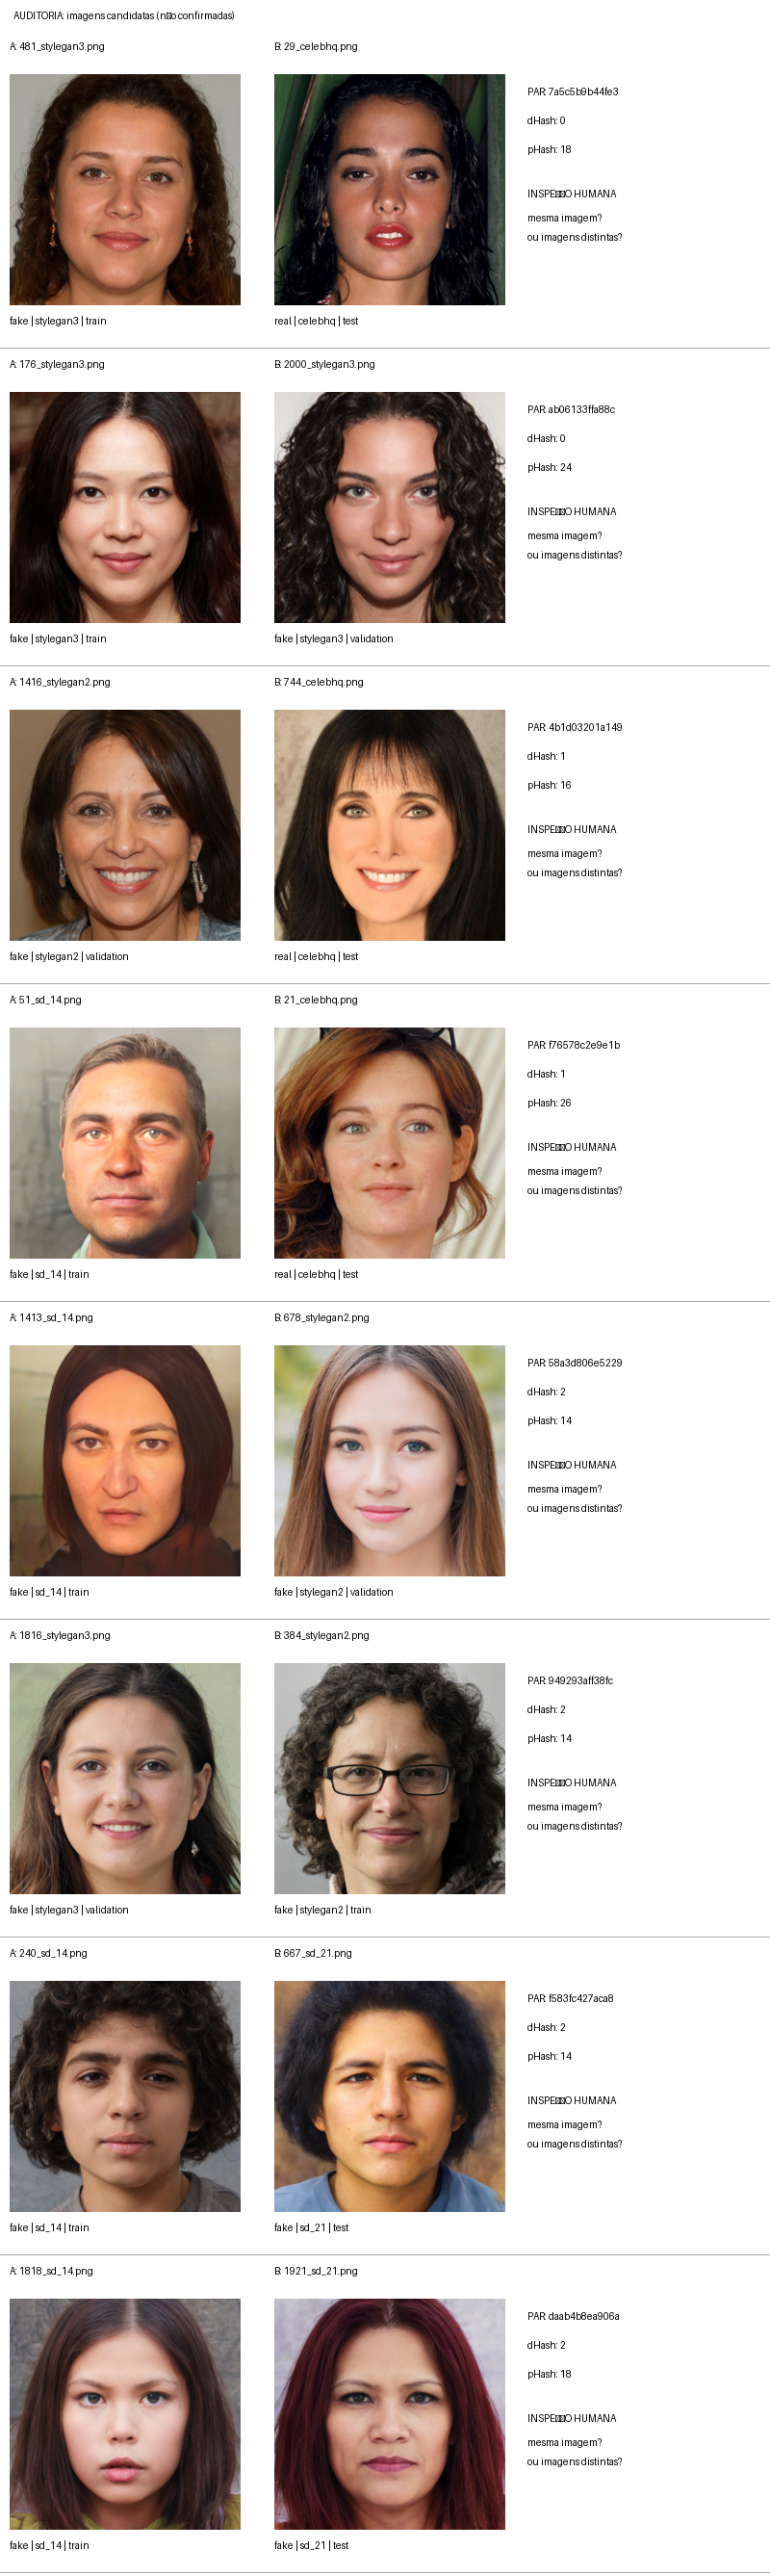

Para gerar as pranchas de todos os candidatos, ative a opção na primeira célula.


In [6]:
def abrir_crop(relativo: str) -> Image.Image:
    arq = PROJETO_DIR / relativo
    with Image.open(arq) as im:
        return ImageOps.exif_transpose(im).convert('RGB').copy()


def desenhar_prancha(lote: pd.DataFrame, arquivo: Path) -> None:
    largura_foto, altura_foto = 240, 240
    largura, altura_linha = 800, 330
    prancha = Image.new('RGB', (largura, 35 + len(lote) * altura_linha), 'white')
    caneta = ImageDraw.Draw(prancha)
    caneta.text((14, 10), 'AUDITORIA: imagens candidatas (não confirmadas)', fill='black')
    for n, (_, par) in enumerate(lote.iterrows()):
        y = 35 + n * altura_linha
        for lado, desloc_x in [('a', 10), ('b', 285)]:
            imagem = abrir_crop(par[f'path_{lado}'])
            thumb = ImageOps.contain(imagem, (largura_foto, altura_foto))
            prancha.paste(thumb, (desloc_x + (largura_foto - thumb.width) // 2,
                                   y + 42 + (altura_foto - thumb.height) // 2))
            nome = Path(par[f'path_{lado}']).name
            caneta.text((desloc_x, y + 7), f'{lado.upper()}: {nome[:33]}', fill='black')
            caneta.text((desloc_x, y + 292),
                        f"{par[f'class_{lado}']} | {par[f'source_{lado}']} | {par[f'split_{lado}']}", fill='black')
        caneta.text((548, y + 54), f"PAR: {str(par.pair_id)[:13]}", fill='black')
        caneta.text((548, y + 84), f"dHash: {par.hamming_distance}", fill='black')
        caneta.text((548, y + 114), f"pHash: {par.phash_distance}", fill='black')
        caneta.text((548, y + 160), 'INSPEÇÃO HUMANA', fill='black')
        caneta.text((548, y + 185), 'mesma imagem?', fill='black')
        caneta.text((548, y + 205), 'ou imagens distintas?', fill='black')
        caneta.line([(0, y + altura_linha - 4), (largura, y + altura_linha - 4)], fill='#aaaaaa')
    prancha.save(arquivo)


def gerar_pranchas(casos: pd.DataFrame, prefixo: str):
    arquivos = []
    for inicio in range(0, len(casos), PARES_POR_PRANCHA):
        lote = casos.iloc[inicio:inicio + PARES_POR_PRANCHA]
        destino = PRANCHAS_DIR / f'{prefixo}_{inicio // PARES_POR_PRANCHA + 1:03d}.png'
        desenhar_prancha(lote, destino)
        arquivos.append(destino)
    return arquivos


if GERAR_PRANCHAS_PRIORITARIAS:
    prioritarios = revisao.loc[revisao.hamming_distance <= LIMIAR_PRIORIDADE]
    arquivos_prioritarios = gerar_pranchas(prioritarios, 'prioritarios_dhash_0a2')
    print(f'Pranchas prioritárias: {len(arquivos_prioritarios)}; pares: {len(prioritarios)}')
    for arquivo in arquivos_prioritarios:
        print('-', arquivo)
    if arquivos_prioritarios:
        display(Image.open(arquivos_prioritarios[0]))

if GERAR_PRANCHAS_TODOS_CROSS_SPLIT:
    arquivos_todos = gerar_pranchas(revisao, 'todos_entre_particoes')
    print(f'Pranchas de todos os candidatos entre partições: {len(arquivos_todos)}')
else:
    print('Para gerar as pranchas de todos os candidatos, ative a opção na primeira célula.')

## 7. Revisão de identidade/origem, quando houver metadados verificáveis

O notebook de treinamento exportou `resnet34_224_identity_origin_review.csv` com os campos `original_group_id` e `identity_id`. **Valores vazios não comprovam que não haja a mesma pessoa ou imagem de origem em partições distintas**. Esta etapa apenas aponta grupos cruzados quando há identificadores preenchidos e confiáveis; não deduz identidade automaticamente pela aparência.

In [7]:
resultado_identidade = {'linhas': 0, 'ids_de_imagem_original_informados': 0,
                        'ids_de_identidade_informados': 0,
                        'grupos_imagem_original_entre_particoes': 0,
                        'grupos_identidade_entre_particoes': 0}

if ARQUIVO_IDENTIDADES.is_file():
    identidade = pd.read_csv(ARQUIVO_IDENTIDADES, dtype=str).fillna('')
    resultado_identidade['linhas'] = len(identidade)
    if not {'path', 'split', 'original_group_id', 'identity_id'}.issubset(identidade.columns):
        print('AVISO: CSV de identidade/origem não possui todas as colunas esperadas.')
    else:
        identidade['path_portatil'] = [caminho_portatil(caminho_local(p, CROPS_DIR, c))
                                       for p, c in zip(identidade.path, identidade.class_name if 'class_name' in identidade.columns
                                                       else [Path(str(p)).parent.name for p in identidade.path])]
        if set(identidade.path_portatil) != set(splits.path_portatil):
            raise ValueError('A planilha de linhagem/identidade não corresponde ao manifesto de partições atual.')
        for coluna, chave_contagem, chave_conflitos in [
            ('original_group_id', 'ids_de_imagem_original_informados', 'grupos_imagem_original_entre_particoes'),
            ('identity_id', 'ids_de_identidade_informados', 'grupos_identidade_entre_particoes'),
        ]:
            informados = identidade.loc[identidade[coluna].astype(str).str.strip().ne('')]
            resultado_identidade[chave_contagem] = len(informados)
            grupos = informados.groupby(coluna)['split'].nunique()
            resultado_identidade[chave_conflitos] = int((grupos > 1).sum())
            print(coluna, '— registros com ID:', len(informados), '| grupos entre partições:',
                  resultado_identidade[chave_conflitos])
        if resultado_identidade['ids_de_identidade_informados'] == 0:
            print('Sem IDs de identidade preenchidos: NÃO é possível certificar ausência de pessoas repetidas.')
else:
    print('Planilha de identidade/origem ausente: esta parte da auditoria permanece limitada.')

original_group_id — registros com ID: 0 | grupos entre partições: 0
identity_id — registros com ID: 0 | grupos entre partições: 0
Sem IDs de identidade preenchidos: NÃO é possível certificar ausência de pessoas repetidas.


## 8. Relatório final **factual**, conforme as decisões registradas

**Antes de executar esta célula após revisar as pranchas:** preencha `revisao_pares_entre_particoes.csv` no Excel/LibreOffice, salve e feche o arquivo. Esta célula **lê novamente a planilha**; não depende de você reexecutar todas as células anteriores.

- Enquanto existirem pares com `pendente`, a revisão **não está concluída**.
- Pares `inconclusivo` não podem ser classificados como “não duplicados”.
- Registros `mesma_imagem` ou `mesma_pessoa_imagens_diferentes` entre treino/validação/teste exigem análise de impacto com o orientador.
- O resultado SHA-256 se aplica a **arquivos binariamente idênticos**; o dHash não prova ausência de vazamento ou duplicação por identidade.

In [8]:
revisao_atual = pd.read_csv(ARQUIVO_REVISAO, dtype={'pair_id': str}, keep_default_na=False)
if revisao_atual.pair_id.duplicated().any() or set(revisao_atual.pair_id) != set(cross.pair_id):
    raise ValueError('Planilha de revisão não corresponde ao conjunto atual de candidatos.')
if not set(revisao_atual.decisao).issubset(DECISOES_VALIDAS):
    raise ValueError(f'Valores inválidos em decisao: {set(revisao_atual.decisao) - DECISOES_VALIDAS}')

contagem_revisoes = revisao_atual.decisao.value_counts().to_dict()
revisados = len(revisao_atual) - contagem_revisoes.get('pendente', 0)
confirmados_imagem = int(contagem_revisoes.get('mesma_imagem', 0))
confirmados_identidade = int(contagem_revisoes.get('mesma_pessoa_imagens_diferentes', 0))
inconclusivos = int(contagem_revisoes.get('inconclusivo', 0))
pendentes = int(contagem_revisoes.get('pendente', 0))

# O status 'completa' significa apenas que todos os candidatos gerados foram revisados,
# sem inferir cobertura perfeita de todos os tipos de duplicatas.
status = 'REVISÃO HUMANA DOS CANDIDATOS CONCLUÍDA' if pendentes == 0 else 'REVISÃO HUMANA PENDENTE'
if inconclusivos or confirmados_imagem or confirmados_identidade:
    status += ' — COM CASOS QUE EXIGEM INTERPRETAÇÃO/ENCAMINHAMENTO'

relatorio = {
    'gerado_em_utc': datetime.now(timezone.utc).isoformat(),
    'cenario': 'source_holdout', 'seed': 42,
    'manifesto_particoes': 'models/audit/resnet34/resnet34_224_source_holdout_seed42_splits.csv',
    'manifesto_sha256': 'models/audit/resnet34/resnet34_224_dataset_manifest.csv',
    'imagens_originais': len(originais), 'crops_validos': len(splits),
    'particoes': {k: int(v) for k, v in contagens.items()},
    'crops_com_hash_sha256_divergente_do_treinamento': int(len(diferencas_hash)),
    'arquivos_originais_com_sha256_repetido': int(len(duplicados_originais)),
    'crops_com_sha256_repetido': int(len(duplicados_crops)),
    'metodo_triagem': 'dHash 64 bits, distância de Hamming <= 5, faixa de busca do treinamento',
    'metodo_ordenacao_auxiliar': 'pHash 64 bits apenas para ordenação/inspeção',
    'pares_candidatos_total': len(candidatos),
    'pares_candidatos_entre_particoes': len(cross),
    'pares_prioritarios_entre_particoes_dhash_0_a_2': int((cross.hamming_distance <= 2).sum()),
    'pares_revisados': int(revisados),
    'pares_pendentes': int(pendentes),
    'pares_confirmados_mesma_imagem_por_revisao': confirmados_imagem,
    'pares_mesma_pessoa_imagens_diferentes_por_revisao': confirmados_identidade,
    'pares_inconclusivos': inconclusivos,
    'decisoes_registradas': {str(k): int(v) for k, v in contagem_revisoes.items()},
    'metadados_de_identidade': resultado_identidade,
    'status': status,
    'observacao': 'dHash/pHash sinalizam semelhança, não provam identidade; a revisão humana cobre os candidatos gerados pela heurística, não todas as possíveis repetições.',
}

with (SAIDA_DIR / 'relatorio_auditoria_duplicatas.json').open('w', encoding='utf-8') as f:
    json.dump(relatorio, f, ensure_ascii=False, indent=2)

texto_relatorio = f"""# Auditoria independente de duplicatas — {datetime.now().date()}

**Escopo:** crops do experimento ResNet34, partições source_holdout/seed 42; os seis experimentos utilizam o mesmo manifesto/partições documentados.

- Arquivos originais: **{len(originais):,}**; crops válidos: **{len(splits):,}**.
- Repartição preservada: treino **{contagens['train']:,}**, validação **{contagens['validation']:,}**, teste **{contagens['test']:,}**.
- Integridade dos crops frente ao SHA-256 do treinamento: **{len(diferencas_hash)} divergências**.
- Arquivos originais com SHA-256 repetido: **{len(duplicados_originais)}** (ocorrências, não pares).
- Crops com SHA-256 repetido: **{len(duplicados_crops)}** (ocorrências, não pares).
- Triagem perceptual dHash 64 bits com distância ≤ {LIMIAR_DHASH}: **{len(candidatos):,} pares candidatos**, sendo **{len(cross):,} entre partições diferentes**.
- Candidatos entre partições com dHash de 0 a 2: **{int((cross.hamming_distance <= 2).sum()):,}**.
- Revisão humana: **{revisados:,} de {len(cross):,} pares analisados**; pendentes **{pendentes:,}**, inconclusivos **{inconclusivos:,}**.
- Confirmados pela inspeção: mesma imagem **{confirmados_imagem:,}**; mesma pessoa em imagens diferentes **{confirmados_identidade:,}**.
- Metadados confiáveis de identidade presentes em {resultado_identidade['ids_de_identidade_informados']} registros; a ausência desses metadados **não** demonstra independência de identidades.

**Situação:** {status}.

**Interpretação:** similaridade perceptual isolada não demonstra duplicação nem vazamento entre partições. A cobertura da auditoria de identidade depende de metadados confiáveis. Quando existem pares confirmados, avaliar impacto nos resultados e documentar decisão com o orientador. O conjunto de teste não foi alterado por este procedimento.

**Evidências:** `duplicatas_exatas_originais.csv`, `duplicatas_exatas_crops.csv`, `candidatos_dhash_todos.csv`, `revisao_pares_entre_particoes.csv`, pranchas locais e manifestos originais do GitHub.
"""
(SAIDA_DIR / 'relatorio_auditoria_duplicatas.md').write_text(texto_relatorio, encoding='utf-8')
print(texto_relatorio)
print('Arquivos exportados para:', SAIDA_DIR)

# Auditoria independente de duplicatas — 2026-10-18

**Escopo:** crops do experimento ResNet34, partições source_holdout/seed 42; os seis experimentos utilizam o mesmo manifesto/partições documentados.

- Arquivos originais: **16,000**; crops válidos: **15,960**.
- Repartição preservada: treino **9,576**, validação **2,394**, teste **3,990**.
- Integridade dos crops frente ao SHA-256 do treinamento: **0 divergências**.
- Arquivos originais com SHA-256 repetido: **0** (ocorrências, não pares).
- Crops com SHA-256 repetido: **0** (ocorrências, não pares).
- Triagem perceptual dHash 64 bits com distância ≤ 5: **2,374 pares candidatos**, sendo **1,224 entre partições diferentes**.
- Candidatos entre partições com dHash de 0 a 2: **18**.
- Revisão humana: **0 de 1,224 pares analisados**; pendentes **1,224**, inconclusivos **0**.
- Confirmados pela inspeção: mesma imagem **0**; mesma pessoa em imagens diferentes **0**.
- Metadados confiáveis de identidade presentes em 0 registros; a ausência